Run UMAP 3D

In [ ]:
import pandas as pd
import json

pca_projections = pd.read_csv(
    "outputs/cellranger/reanalyze/ptr_nextseq_batch1_rs17/outs/analysis/pca/gene_expression_10_components/projection.csv",
    index_col=0
)
params = {
    "n_neighbors": 30,
    "n_components": 3,
    "metric": "correlation",
    "n_epochs": None,
    "learning_rate": 1,
    "init": "random",
    "min_dist": 0.3,
    "spread": 1,
    "set_op_mix_ratio": 1,
    "local_connectivity": 1, 
    "repulsion_strength": 1,
    "negative_sample_rate": 5,
    "random_state": 17,
    "metric_kwds": None,
    "n_jobs": -1
}

reducer = umap.UMAP(**params)
umap_projections = reducer.fit_transform(pca_projections)
out_df = pd.DataFrame(
    umap_projections,
    index=pca_projections.index,
    columns=["UMAP-1", "UMAP-2"]
)
out_df.index.name = "Barcode"
out_df.to_csv(argv[1])


Plot UMAP 3D

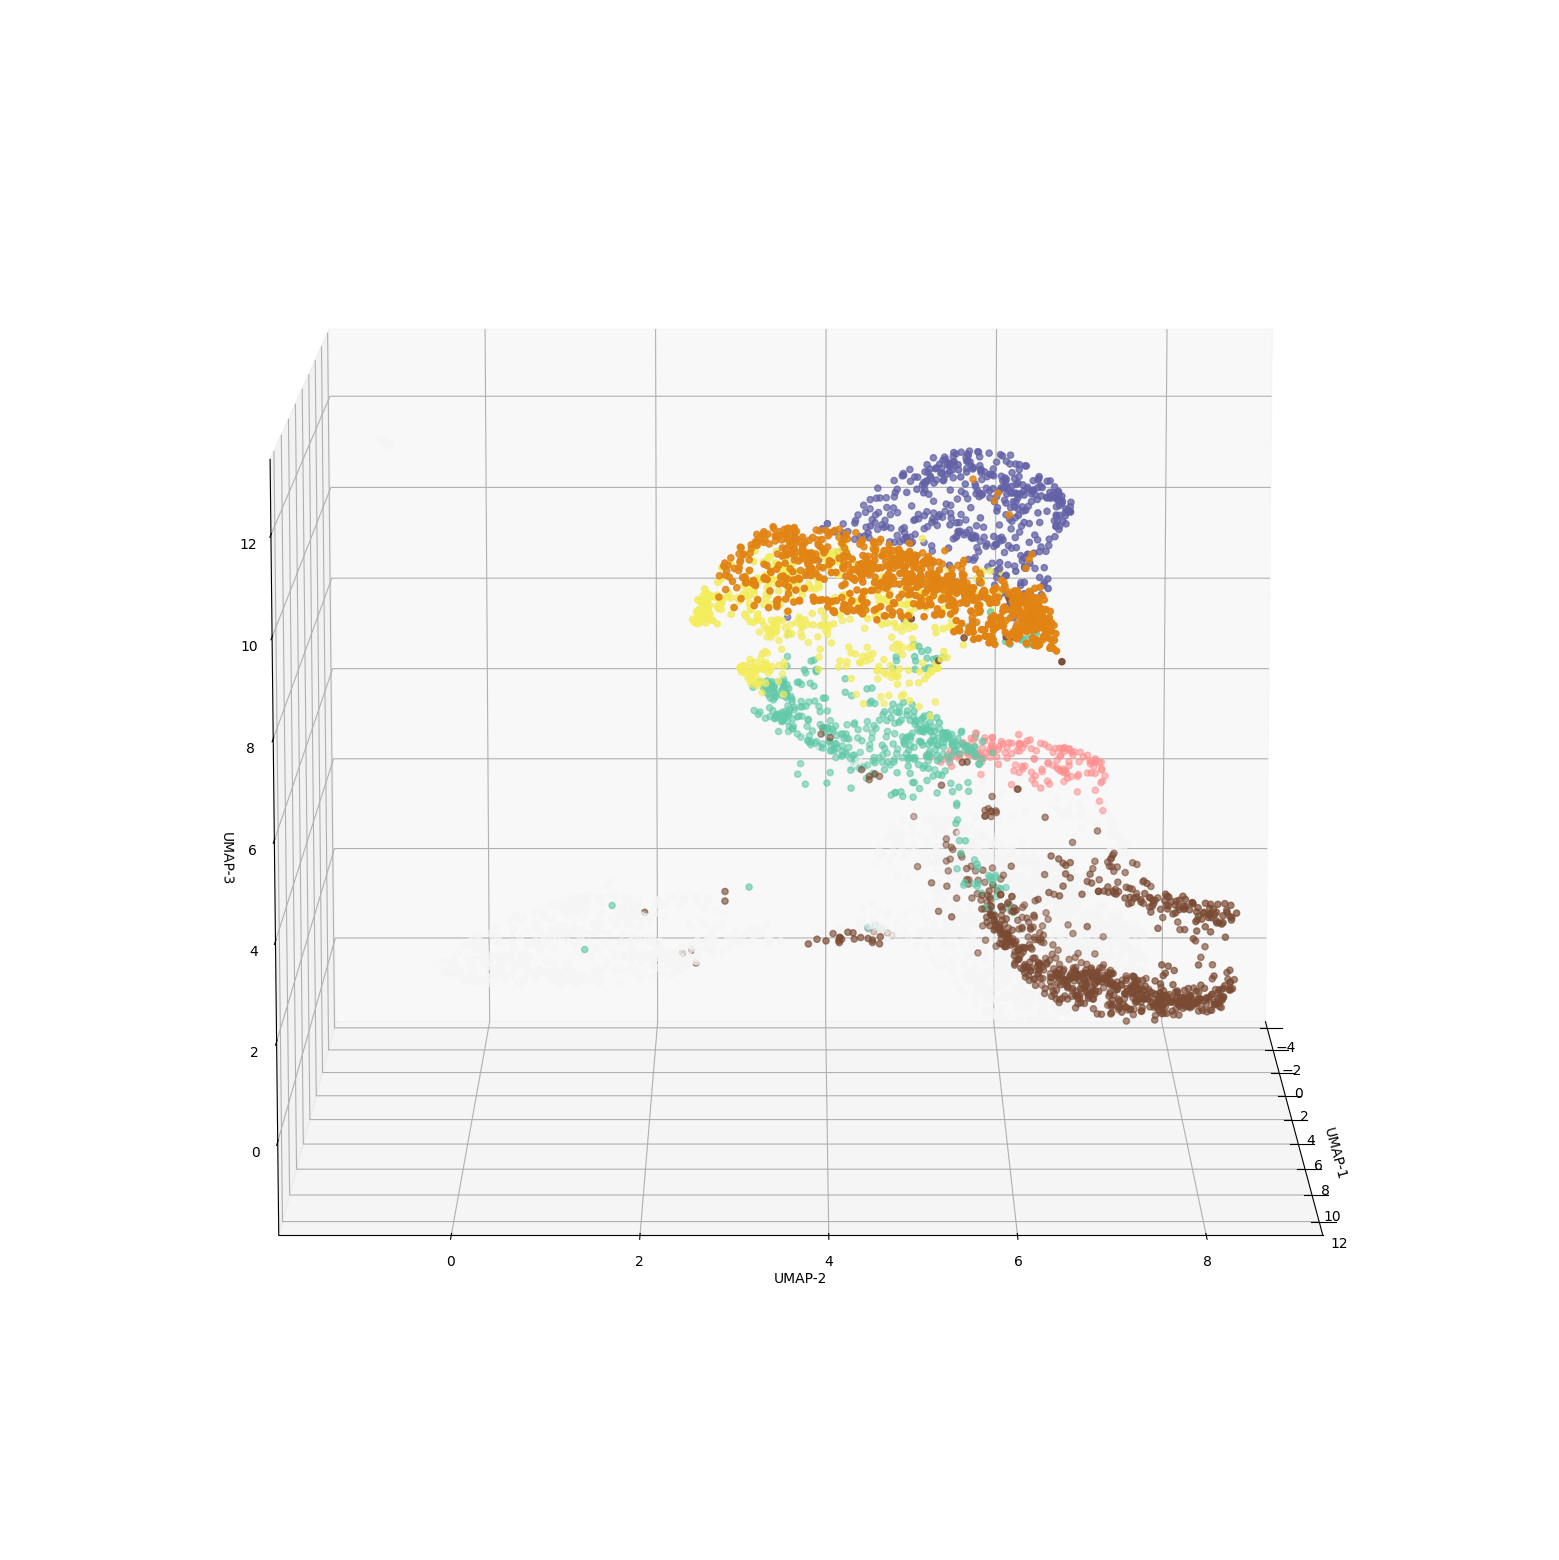

In [1]:
from mpl_toolkits.mplot3d import axes3d
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import pandas as pd
import os


# vars
umap_projection = "test/umap3d/umap_3d.csv"
cell_ident = "outputs/seurat_integration/groups/ptr_tenx_batch1/rs17/cell_identities.csv"
output = "test/for_blake/umap3d_grey_masked.gif"
palette = {
    3: "#E28413",
    4: "#F3EC5B",
    8: "#FF8F8F",
    6: "#6362A7",
    5: "#61C9A8",
    2: "#7A4A33",
    1: "whitesmoke",
    7: "whitesmoke",
    9: "whitesmoke",
    10: "whitesmoke",
}

# load data
umap_projection = pd.read_csv(umap_projection)
umap_projection["Barcode"] = [f"ptr_tenx_batch1_rs17:{i}" for i in umap_projection["Barcode"]]
cell_ident = pd.read_csv(cell_ident)
merged_data = pd.merge(umap_projection, cell_ident, on="Barcode")
merged_data["Sample"] = [x.split(":")[0] for x in merged_data["Barcode"]]

# create output directory
os.makedirs(os.path.dirname(output), exist_ok=True)

# create figure
fig = plt.figure(figsize=(30,20))
ax = fig.add_subplot(projection="3d")
colors = merged_data["Cluster"].map(palette)
ax.scatter(
    merged_data["UMAP-1"],
    merged_data["UMAP-2"],
    merged_data["UMAP-3"],
    color=colors,
)

# Set the axis labels
ax.set_xlabel("UMAP-1")
ax.set_ylabel("UMAP-2")
ax.set_zlabel("UMAP-3")

# define animation function
def animate(i):
    ax.view_init(10, i, 0)
    return (ax,)

ani = animation.FuncAnimation(fig, animate, repeat=True, frames=361, interval=50)
writer = animation.PillowWriter(fps=15, metadata=dict(artist='Me'), bitrate=1800)
ani.save(output, writer=writer)

Test plot new seurat integrated umap

<Axes: xlabel='UMAP-1', ylabel='UMAP-2'>

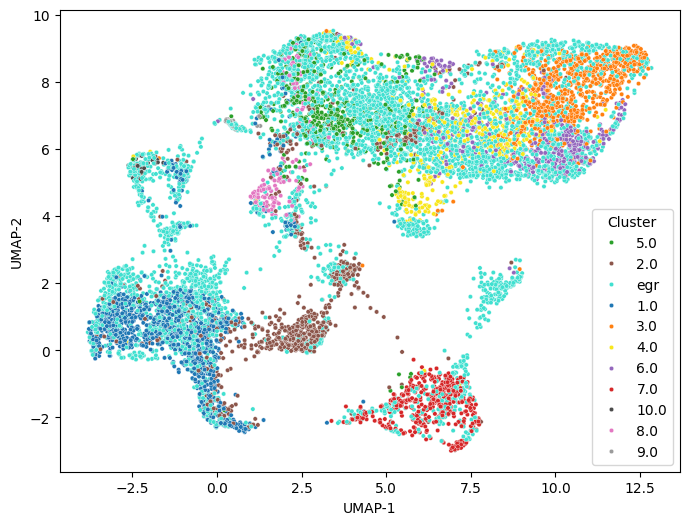

In [34]:
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

umap = pd.read_csv("outputs/seurat_integration/group1/rs17/umap_projections_new.csv")
ptr_barcode2color = pd.read_csv("outputs/seurat_integration/barcode2color/tung_batch1_rs17.csv")
ptr_barcode2color["Barcode"] = ["tung_batch1_rs17_" + i for i in ptr_barcode2color["Barcode"]]
umap = umap.merge(ptr_barcode2color, on="Barcode", how="left")
umap["Color"] = umap["Color"].fillna("turquoise")
umap["Cluster"] = umap["Cluster"].fillna("egr")
umap["Sample"] = umap["Barcode"].apply(lambda x: x.split("_")[0])

fig, ax = plt.subplots(figsize=(4*2, 3*2))
sns.scatterplot(
    data=umap.sample(frac=1, random_state=0),
    x="UMAP-1",
    y="UMAP-2",
    hue="Cluster",
    palette=dict(zip(umap["Cluster"], umap["Color"])),
    ax=ax,
    s=10
)
# sns.scatterplot(
#     data=umap,
#     x="UMAP-1",
#     y="UMAP-2",
#     hue="Sample",
#     ax=ax,
#     s=10
# )

In [17]:
umap["Barcode"]

0         tung_batch1_rs17_AAACCTGAGCACCGCT-1
1         tung_batch1_rs17_AAACCTGCAAGAGTCG-1
2         tung_batch1_rs17_AAACCTGCACATTCGA-1
3         tung_batch1_rs17_AAACCTGGTAAATGAC-1
4         tung_batch1_rs17_AAACCTGGTCATCGGC-1
                        ...                  
9836    egr_nextseq_batch1_rs17_Eg20072328379
9837    egr_nextseq_batch1_rs17_Eg20072328380
9838    egr_nextseq_batch1_rs17_Eg20072328381
9839    egr_nextseq_batch1_rs17_Eg20072328382
9840    egr_nextseq_batch1_rs17_Eg20072328383
Name: Barcode, Length: 9841, dtype: object

In [13]:
umap

# ----- OLD SEURAT PIPELINE -----

Plot Seurat-30PC-Ptr-NN-colored Lch UMAP 

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
import os

# get umap projections
umap = pd.read_csv(
    "outputs/cellranger/reanalyze/lch_tenx_batch1_rs17/outs/analysis/umap/gene_expression_2_components/projection.csv",
    index_col=0
)

# get cell colors
tar_cell_color = pd.read_csv("test/barcode2color/lch_tenx_batch1_rs17.csv", index_col=0)[["Cluster","Color"]]

# merge umap and cell colors
umap = umap.merge(tar_cell_color, left_index=True, right_index=True)

# plot
fig, ax = plt.subplots(figsize=(4*2, 3*2))
sns.scatterplot(
    data=umap.sample(frac=1, random_state=0),
    x="UMAP-1",
    y="UMAP-2",
    hue="Cluster",
    palette=dict(zip(umap["Cluster"], umap["Color"])),
    ax=ax,
    s=10
)
ax.set_title("Seurat-30PC-Ptr-NN-annotated Lch CellRanger-10PC-UMAP")

# save figure
os.makedirs("test/seurat_PC30_NN_annotated_cellranger_UMAP", exist_ok=True)
fig.savefig("test/seurat_PC30_NN_annotated_cellranger_UMAP/umap_lch.pdf", bbox_inches="tight")
fig.savefig("test/seurat_PC30_NN_annotated_cellranger_UMAP/umap_lch.png", dpi=300, bbox_inches="tight")

Plot Seurat-30PC-Ptr-NN-colored Tar UMAP 

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

# get umap projections
umap = pd.read_csv(
    "outputs/cellranger/reanalyze/tar_nextseq_batch1_rs17/outs/analysis/umap/gene_expression_2_components/projection.csv",
    index_col=0
)

# get cell colors
tar_cell_color = pd.read_csv("test/barcode2color/tar_nextseq_batch1_rs17.csv", index_col=0)[["Cluster","Color"]]

# merge umap and cell colors
umap = umap.merge(tar_cell_color, left_index=True, right_index=True)

# plot
fig, ax = plt.subplots(figsize=(4*2, 3*2))
sns.scatterplot(
    data=umap,
    x="UMAP-1",
    y="UMAP-2",
    hue="Cluster",
    palette=dict(zip(umap["Cluster"], umap["Color"])),
    ax=ax,
    s=10
)
ax.set_title("Seurat-30PC-Ptr-NN-annotated Tar CellRanger-10PC-UMAP")

# save
fig.savefig("test/seurat_PC30_NN_annotated_cellranger_UMAP/umap_tar.pdf", bbox_inches="tight")
fig.savefig("test/seurat_PC30_NN_annotated_cellranger_UMAP/umap_tar.png", dpi=300, bbox_inches="tight")

Plot Seurat-30PC-Ptr-NN-colored Egr UMAP 

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

# get UMAP coordinates
egr_umap_projections = pd.read_csv(
    "outputs/cellranger/reanalyze/egr_nextseq_batch1_rs17/outs/analysis/umap/gene_expression_2_components/projection.csv"
)

# get cell color assignment
egr_cell_color = pd.read_csv("test/barcode2color/egr_nextseq_batch1_rs17.csv")

# merge
egr_umap_projections = egr_umap_projections.merge(egr_cell_color, left_on="Barcode", right_on="Barcode")

# plot
fig, ax = plt.subplots(figsize=(4*2, 3*2))
sns.scatterplot(
    data=egr_umap_projections,
    x="UMAP-1",
    y="UMAP-2",
    hue="Cluster",
    palette=dict(zip(egr_cell_color["Cluster"], egr_cell_color["Color"])),
    ax=ax,
    s=10
)
ax.set_title("Seurat-30PC-Ptr-NN-annotated Egr CellRanger-10PC-UMAP")

# save
fig.savefig("test/seurat_PC30_NN_annotated_cellranger_UMAP/umap_egr.pdf", bbox_inches="tight")
fig.savefig("test/seurat_PC30_NN_annotated_cellranger_UMAP/umap_egr.png", dpi=300, bbox_inches="tight")

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

# get UMAP coordinates
egr_umap_projections = pd.read_csv(
    "outputs/cellranger/reanalyze/tung_batch1_rs17/outs/analysis/umap/gene_expression_2_components/projection.csv"
)

# get cell color assignment
egr_cell_color = pd.read_csv("test/barcode2color/tung_batch1_rs17.csv")

# merge
egr_umap_projections = egr_umap_projections.merge(egr_cell_color, left_on="Barcode", right_on="Barcode")

# plot
fig, ax = plt.subplots(figsize=(4*2, 3*2))
sns.scatterplot(
    data=egr_umap_projections,
    x="UMAP-1",
    y="UMAP-2",
    hue="Cluster",
    palette=dict(zip(egr_cell_color["Cluster"], egr_cell_color["Color"])),
    ax=ax,
    s=10
)
ax.set_title("Ptr CellRanger-10PC-UMAP")

# save
fig.savefig("test/seurat_PC30_NN_annotated_cellranger_UMAP/umap_ptr.pdf", bbox_inches="tight")
fig.savefig("test/seurat_PC30_NN_annotated_cellranger_UMAP/umap_ptr.png", dpi=300, bbox_inches="tight")

Annotated cell type based on nearest neighbor on Seurat 30-PC

In [37]:
from sklearn.metrics.pairwise import euclidean_distances
import pandas as pd

# vars
path_cell_cluster_ptr = "outputs/seurat_integration/barcode2color/tung_batch1_rs17.csv"
path_seurat_umap_projections = "outputs/seurat_integration/group1/umap_projections.csv"
path_seurat_pca_projections = "outputs/seurat_integration/group1/pca_projection.csv"

# load
cell_cluster_ptr = pd.read_csv(path_cell_cluster_ptr, index_col=0)
cell_cluster_ptr.index = ["tung_batch1_rs17_" + i for i in cell_cluster_ptr.index]
umap_projections = pd.read_csv(path_seurat_umap_projections, index_col=0)
pca_projections = pd.read_csv(path_seurat_pca_projections, index_col=0)

# compute euclidean distances
pca_distances = euclidean_distances(pca_projections, pca_projections)
pca_distances = pd.DataFrame(pca_distances, index=pca_projections.index, columns=pca_projections.index)

# get nearest tung_batch1_rs17 cell for each seurat cell
pca_distance2tung = pca_distances.loc[:, cell_cluster_ptr.index]
pca_NN = pca_distance2tung.idxmin(axis=1)

# get cluster and color based on NN
pca_projections["Cluster"] = cell_cluster_ptr.loc[pca_NN, "Cluster"].values
pca_projections["Color"] = cell_cluster_ptr.loc[pca_NN, "Color"].values

# write only row with index containing "tung" or "egr"
pca_projections_rosid = pca_projections[pca_projections.index.str.contains("tung|egr")]
pca_projections_rosid.to_csv("test/to_Hung/seurat_30PC_rosid.csv")

# write to file
pca_projections.to_csv("test/seurat_PC30_NN_annotated.csv")

In [16]:
import pandas as pd
import os

pca_projections = pd.read_csv("test/seurat_PC30_NN_annotated.csv", index_col=0)
os.makedirs("test/barcode2color", exist_ok=True)

pca_projections["Sample"] = ["_".join(i.split("_")[:-1]) for i in pca_projections.index]
pca_projections["Barcode"] = [i.split("_")[-1] for i in pca_projections.index]

for sample in pca_projections["Sample"].unique():
    sub = pca_projections[pca_projections["Sample"] == sample]
    sub[["Barcode", "Cluster", "Color"]].to_csv(f"test/barcode2color/{sample}.csv", index=False)

In [17]:
pd.read_csv("test/barcode2color/tung_batch1_rs17.csv")

,Barcode,Cluster,Color
0,AAACCTGAGCACCGCT-1,8,#E377C2
1,AAACCTGCAAGAGTCG-1,7,#D62728
2,AAACCTGCACATTCGA-1,3,#FF7F0F
3,AAACCTGGTAAATGAC-1,3,#FF7F0F
4,AAACCTGGTCATCGGC-1,1,#1F77B4
...,...,...,...
4855,TTTGTCAGTTCAGGCC-1,2,#8C564B
4856,TTTGTCATCATAGCAC-1,1,#1F77B4
4857,TTTGTCATCCGAGCCA-1,8,#E377C2
4858,TTTGTCATCCTTTACA-1,6,#9467BD


In [20]:
# 
path_ptr_cellranger_10pc = "outputs/cellranger/reanalyze/tung_batch1_rs17/outs/analysis/pca/gene_expression_10_components/projection.csv"
path_egr_cellranger_10pc = "outputs/cellranger/reanalyze/egr_nextseq_batch1_rs17/outs/analysis/pca/gene_expression_10_components/projection.csv"

# 
ptr_cellranger_10pc = pd.read_csv(path_ptr_cellranger_10pc, index_col=0)
egr_cellranger_10pc = pd.read_csv(path_egr_cellranger_10pc, index_col=0)

#
egr_cell_in_seurat = [i.split("_")[-1] for i in pca_projections[pca_projections.index.str.contains("egr")].index]
egr_cellranger_10pc = egr_cellranger_10pc.loc[egr_cell_in_seurat, :]

# annotate cluster and color
ptr_cellranger_10pc["Cluster"] = list(pca_projections_rosid.loc[["tung_batch1_rs17_" + i for i in ptr_cellranger_10pc.index], "Cluster"])
ptr_cellranger_10pc["Color"] = list(pca_projections_rosid.loc[["tung_batch1_rs17_" + i for i in ptr_cellranger_10pc.index], "Color"])
egr_cellranger_10pc["Cluster"] = list(pca_projections_rosid.loc[["egr_nextseq_batch1_rs17_" + i for i in egr_cellranger_10pc.index], "Cluster"])
egr_cellranger_10pc["Color"] = list(pca_projections_rosid.loc[["egr_nextseq_batch1_rs17_" + i for i in egr_cellranger_10pc.index], "Color"])

# write to file
ptr_cellranger_10pc.to_csv("test/to_Hung/ptr_cellranger_10pc.csv")
egr_cellranger_10pc.to_csv("test/to_Hung/egr_cellranger_10pc.csv")

Trim _Populus_ cluster

0. Exclude Populus cells that show top 10% variable intra-cluster pairwise distance on Seurat 30PC and UMAP-1&2

In [ ]:
from sklearn.metrics.pairwise import euclidean_distances
from scipy.stats import pearsonr
from scipy.spatial.distance import cosine
import pandas as pd

# vars
path_cell_cluster = "outputs/seurat_integration/barcode2color/tung_batch1_rs17.csv"
path_seurat_umap_projections = "outputs/seurat_integration/group1/umap_projections.csv"
path_seurat_pca_projections = "outputs/seurat_integration/group1/pca_projection.csv"

# load
df_cell_cluster = pd.read_csv(path_cell_cluster, index_col=0)
umap_projections = pd.read_csv(path_seurat_umap_projections, index_col=0)
pca_projections = pd.read_csv(path_seurat_pca_projections, index_col=0)

# preprocess
umap_projections["sample"] = ["_".join(x.split("_")[:-1]) for x in umap_projections.index]
umap_projections["barcode"] = [x.split("_")[-1] for x in umap_projections.index]
tung_umap_projections = umap_projections[umap_projections["sample"] == "tung_batch1_rs17"]
pca_projections["sample"] = ["_".join(x.split("_")[:-1]) for x in pca_projections.index]
pca_projections["barcode"] = [x.split("_")[-1] for x in pca_projections.index]
tung_pca_projections = pca_projections[pca_projections["sample"] == "tung_batch1_rs17"]

# calcuate the variance in intra-cluster distances on the UMAP and PCA projections for each cluster
for cluster in df_cell_cluster["Cluster"].unique():
    # get the cell barcodes for the cluster
    cluster_barcodes = df_cell_cluster[df_cell_cluster["Cluster"] == cluster].index
    
    # get the UMAP/PCA projections for the cluster
    cluster_umap = tung_umap_projections[tung_umap_projections["barcode"].isin(cluster_barcodes)]
    cluster_pca = tung_pca_projections[tung_pca_projections["barcode"].isin(cluster_barcodes)]
    
    # calculate the intra-cluster pairwise distances
    cluster_umap_distances = euclidean_distances(
        cluster_umap[["UMAP-1", "UMAP-2"]], 
        cluster_umap[["UMAP-1", "UMAP-2"]]
    )
    cluster_umap_distances = pd.DataFrame(cluster_umap_distances, index=cluster_umap.index, columns=cluster_umap.index)
    cluster_pca_distances = euclidean_distances(
        cluster_pca.iloc[:, :30], 
        cluster_pca.iloc[:, :30]
    )
    cluster_pca_distances = pd.DataFrame(cluster_pca_distances, index=cluster_pca.index, columns=cluster_pca.index)
    
    # for each cell in cluster calculate cosine similarity for UMAP and PCA distances
    pearson_r = pd.Series(index=cluster_umap_distances.index)
    for cell in cluster_umap_distances.index:
        pearson_r[cell] = pearsonr(
            cluster_umap_distances[cell],
            cluster_pca_distances[cell]
        ).statistic
        
    # cell barcodes of top 10% lowest cosine similarity
    index_sorted = pearson_r.sort_values().index
    top_10 = pearson_r.sort_values().head(int(len(pearson_r) * 0.1)).index
    
    # re-assign cluster
    df_cell_cluster.loc[[x.split("_")[-1] for x in top_10], "Cluster"] = 99
    # break

Assign cell identity according to the nearest _Populus_ cell on Seurat PC

In [ ]:
# assign cluster based on sample_barcode
ptr_umap_projections = umap_projections[umap_projections["sample"] == "tung_batch1_rs17"]
ptr_umap_projections["cluster"] = df_cell_cluster.loc[ptr_umap_projections["barcode"], "Cluster"].values

import matplotlib.pyplot as plt
import seaborn as sns
fig, ax = plt.subplots(figsize=(27, 18))
palette = dict(zip(df_cell_cluster["Cluster"], df_cell_cluster["Color"]))
palette[99] = "cyan"
sns.scatterplot(
    x="UMAP-1",
    y="UMAP-2",
    hue="cluster",
    data=ptr_umap_projections,
    ax=ax,
    s=50,
    palette=palette
)

1. Trim cluster based on distance to cluster centroid (average) on Cell Ranger 10-PC 

In [ ]:
import pandas as pd

# var
path_cellranger_pca_projection = "outputs/cellranger/reanalyze/tung_batch1_rs17/outs/analysis/pca/gene_expression_10_components/projection.csv"
path_cellranger_clusters = "outputs/cellranger/reanalyze/tung_batch1_rs17/outs/analysis/clustering/gene_expression_kmeans_10_clusters/clusters.csv"
path_seurat_umap_projection = "outputs/seurat_integration/group1/umap_projections.csv"

# load
cellranger_pca_projection = pd.read_csv(path_cellranger_pca_projection, index_col=0)
cellranger_clusters = pd.read_csv(path_cellranger_clusters, index_col=0)
seurat_umap_projection = pd.read_csv(path_seurat_umap_projection, index_col=0)

# merge pca projection with clusters info
cellranger_pca_projection = cellranger_pca_projection.merge(cellranger_clusters, left_index=True, right_index=True)

# find cluster centroids on PCA
centroids = cellranger_pca_projection.groupby("Cluster").mean()

# calulate distance to centroid
distance_to_centroid = cellranger_pca_projection.apply(
    lambda x: ((x - centroids.loc[cellranger_clusters.loc[x.name, "Cluster"]])**2).sum()**-2, axis=1
)
cellranger_pca_projection["d2c"] = distance_to_centroid
cellranger_pca_projection.head()

# move cells further than the 90th percentile in each cluster to new cluster 99
percentile = 90
cellranger_pca_projection_filtered = cellranger_pca_projection.copy()
for cluster in cellranger_pca_projection_filtered["Cluster"].unique():
    cluster_cells = cellranger_pca_projection_filtered[cellranger_pca_projection_filtered["Cluster"] == cluster]
    threshold = cluster_cells["d2c"].quantile(percentile/100)
    cellranger_pca_projection_filtered.loc[
        (cellranger_pca_projection_filtered["Cluster"] == cluster) & (cellranger_pca_projection_filtered["d2c"] > threshold),
        "Cluster"
    ] = 99
    
# plot seurat umap projection with reclustered cellranger clusters
seurat_umap_projection["Sample"] = ["_".join(x.split("_")[:-1]) for x in seurat_umap_projection.index]
seurat_umap_projection = seurat_umap_projection[seurat_umap_projection["Sample"] == "tung_batch1_rs17"]
seurat_umap_projection["Barcode"] = [x.split("_")[-1] for x in seurat_umap_projection.index]
seurat_umap_projection["Color"] = seurat_umap_projection["Barcode"].map(cellranger_pca_projection_filtered["Cluster"])

import matplotlib.pyplot as plt
import seaborn as sns
fig, ax = plt.subplots(figsize=(27, 18))
sns.scatterplot(
    x="UMAP-1",
    y="UMAP-2", 
    data=seurat_umap_projection, 
    hue="Color", 
    palette=["#1F77B4","#8C564B","#FF7F0F","#F8E71C","#2AA02A","#9467BD","#D62728","#E377C2","#9B9B9B","#4B4B4B","cyan"],
)
# figure title 
plt.title("Populus Seurat UMAP projection with 90% high-confidence intra-cluster cells\n(Cell Ranger 10-PC, Centroid = average)", fontsize=20)

2. Trim cluster based on distance to centroid (median) on Seurat integrated UMAP projections

In [ ]:
import pandas as pd
import numpy as np

# vars
path_cellranger_cluster = "outputs/seurat_integration/barcode2color/tung_batch1_rs17.csv"
path_seurat_pca_projection = "outputs/seurat_integration/group1/pca_projection.csv"
path_seurat_umap_projections = "outputs/seurat_integration/group1/umap_projections.csv"

# load
cellranger_clusters = pd.read_csv(path_cellranger_cluster, index_col=0)
seurat_pca_projections = pd.read_csv(path_seurat_pca_projection, index_col=0)
seurat_umap_projections = pd.read_csv(path_seurat_umap_projections, index_col=0)

# preprocess data
# preprocess umap projections
seurat_umap_projections["sample"] = ["_".join(x.split("_")[:-1]) for x in seurat_umap_projections.index]
seurat_umap_projections["barcode"] = [x.split("_")[-1] for x in seurat_umap_projections.index]

# preprocess pca projections
seurat_pca_projections["sample"] = ["_".join(x.split("_")[:-1]) for x in seurat_pca_projections.index]
seurat_pca_projections["barcode"] = [x.split("_")[-1] for x in seurat_pca_projections.index]

# preprocess cellranger clusters
palette = dict(zip(cellranger_clusters["Cluster"], cellranger_clusters["Color"]))

# trim Ptr cluster
# get umap projections for Ptr clusters
tung_seurat_umap_projections = seurat_umap_projections[seurat_umap_projections["sample"] == "tung_batch1_rs17"]
tung_seurat_umap_projections.loc[:, "cluster"] = tung_seurat_umap_projections["barcode"].map(cellranger_clusters["Cluster"])

# calculate distance to centroid and move outliers to cluster 99
for q in [1, .98, .95, .90]:
    for cluster in tung_seurat_umap_projections["cluster"].unique():
        cluster_cells = tung_seurat_umap_projections[tung_seurat_umap_projections["cluster"] == cluster]
        cluster_centroid = cluster_cells[["UMAP-1", "UMAP-2"]].median()
        distance_to_centroid = cluster_cells.apply(
            lambda x: np.sqrt(((x[["UMAP-1", "UMAP-2"]] - cluster_centroid)**2).sum()), axis=1
        )
        threshold = distance_to_centroid.quantile(q)
        outlier = cluster_cells[distance_to_centroid > threshold].index
        tung_seurat_umap_projections.loc[outlier, "cluster"] = 99
        
    # plot
    import matplotlib.pyplot as plt
    import seaborn as sns
    fig, ax = plt.subplots(figsize=(27, 18))
    palette[99] = "cyan"
    sns.scatterplot(
        x="UMAP-1",
        y="UMAP-2", 
        data=tung_seurat_umap_projections, 
        hue="cluster", 
        palette=palette,
    )
    # figure title
    plt.title(f"Populus Seurat UMAP projection with {q*100}% high-confidence intra-cluster cells\n(Seurat UMAP1&2, Centroid = median)", fontsize=20)
    plt.savefig(f"test/trim_Ptr_cluster/seurat_umap1&2_cetroid=median_cutoff={q*100}%.png")
    tung_seurat_umap_projections.loc[:, "cluster"].to_csv(f"test/trim_Ptr_cluster/seurat_umap1&2_cetroid=median_cutoff={q*100}%.csv")

In [ ]:
import pandas as pd
import numpy as np

# vars
path_cellranger_cluster = "outputs/seurat_integration/barcode2color/tung_batch1_rs17.csv"
path_seurat_pca_projection = "outputs/seurat_integration/group1/pca_projection.csv"
path_seurat_umap_projections = "outputs/seurat_integration/group1/umap_projections.csv"

# load
cellranger_clusters = pd.read_csv(path_cellranger_cluster, index_col=0)
seurat_pca_projections = pd.read_csv(path_seurat_pca_projection, index_col=0)
seurat_umap_projections = pd.read_csv(path_seurat_umap_projections, index_col=0)

# preprocess data
# preprocess umap projections
seurat_umap_projections["sample"] = ["_".join(x.split("_")[:-1]) for x in seurat_umap_projections.index]
seurat_umap_projections["barcode"] = [x.split("_")[-1] for x in seurat_umap_projections.index]

# preprocess pca projections
seurat_pca_projections["sample"] = ["_".join(x.split("_")[:-1]) for x in seurat_pca_projections.index]
seurat_pca_projections["barcode"] = [x.split("_")[-1] for x in seurat_pca_projections.index]

# preprocess cellranger clusters
palette = dict(zip(cellranger_clusters["Cluster"], cellranger_clusters["Color"]))

# trim Ptr cluster
# get umap projections for Ptr clusters
tung_seurat_umap_projections = seurat_umap_projections[seurat_umap_projections["sample"] == "tung_batch1_rs17"]
tung_seurat_umap_projections.loc[:, "cluster"] = tung_seurat_umap_projections["barcode"].map(cellranger_clusters["Cluster"])

# trim Ptr cluster
# get pca projections for Ptr clusters
tung_seurat_pca_projections = seurat_pca_projections[seurat_pca_projections["sample"] == "tung_batch1_rs17"]
tung_seurat_pca_projections.loc[:, "cluster"] = tung_seurat_pca_projections["barcode"].map(cellranger_clusters["Cluster"])

# calculate distance to centroid and move outliers to cluster 99
for q in [1, .98, .95, .90]:
    for cluster in tung_seurat_pca_projections["cluster"].unique():
        cluster_cells = tung_seurat_pca_projections[tung_seurat_pca_projections["cluster"] == cluster]
        cluster_centroid = cluster_cells.iloc[:, 0:30].median()
        distance_to_centroid = cluster_cells.apply(
            lambda x: np.sqrt(((x.iloc[0:30] - cluster_centroid)**2).sum()), axis=1
        )
        threshold = distance_to_centroid.quantile(q)
        outlier = cluster_cells[distance_to_centroid > threshold].index
        tung_seurat_umap_projections.loc[outlier, "cluster"] = 99
        
    # plot
    import matplotlib.pyplot as plt
    import seaborn as sns
    fig, ax = plt.subplots(figsize=(27, 18))
    palette[99] = "cyan"
    sns.scatterplot(
        x="UMAP-1",
        y="UMAP-2", 
        data=tung_seurat_umap_projections, 
        hue="cluster", 
        palette=palette,
    )
    # figure title
    plt.title(f"Populus Seurat UMAP projection with {q*100}% high-confidence intra-cluster cells\n(Seurat 30PC, Centroid = median)", fontsize=20)
    plt.savefig(f"test/trim_Ptr_cluster/seurat_30pc_cetroid=median_cutoff={q*100}%.png")

In [ ]:
cluster_cells.apply(lambda x: x.iloc[0:30] - cluster_centroid, axis=1)

OFC: Ratio of Populus Cell Ranger clusters in Seurat clusters

In [2]:
import pandas as pd

# var
path_ptr_cellranger_cluster = "outputs/seurat_integration/barcode2color/tung_batch1_rs17.csv"
path_seurat_cluster = "outputs/seurat_integration/group1/clusters.csv"

# load
ptr_cellranger_cluster = pd.read_csv(path_ptr_cellranger_cluster, index_col=0)
seurat_cluster = pd.read_csv(path_seurat_cluster, index_col=0)

# get ptr part
seurat_cluster["sample"] = [x.split("_")[0] for x in seurat_cluster.index]
ptr_seurat_cluster = seurat_cluster.loc[seurat_cluster["sample"] == "tung", :]
ptr_seurat_cluster["barcode"] = [x.split("_")[-1] for x in ptr_seurat_cluster.index]
ptr_seurat_cluster["Seurat_cluster"] = ptr_seurat_cluster["Cluster"]
ptr_seurat_cluster["CellRanger_cluster"] = ptr_seurat_cluster["barcode"].map(ptr_cellranger_cluster["Cluster"])


/tmp/ipykernel_1385520/3699801949.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ptr_seurat_cluster["barcode"] = [x.split("_")[-1] for x in ptr_seurat_cluster.index]
/tmp/ipykernel_1385520/3699801949.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ptr_seurat_cluster["Seurat_cluster"] = ptr_seurat_cluster["Cluster"]
/tmp/ipykernel_1385520/3699801949.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value ins

In [27]:
ptr_cellranger_cluster

,Cluster,Color
Barcode,,
AAACCTGAGCACCGCT-1,8,#E377C2
AAACCTGCAAGAGTCG-1,7,#D62728
AAACCTGCACATTCGA-1,3,#FF7F0F
AAACCTGGTAAATGAC-1,3,#FF7F0F
AAACCTGGTCATCGGC-1,1,#1F77B4
...,...,...
TTTGTCAGTTCAGGCC-1,2,#8C564B
TTTGTCATCATAGCAC-1,1,#1F77B4
TTTGTCATCCGAGCCA-1,8,#E377C2


In [32]:
# get proportion of CellRanger cluster in each Seurat cluster
count = ptr_seurat_cluster.groupby("Seurat_cluster")["CellRanger_cluster"].value_counts().unstack()
count[count.isna()] = 0

# annotate Seurat cluster with CellRanger cluster (as integer)
seurat_cluster["CellRanger_cluster"] = seurat_cluster["Cluster"].map(count.idxmax(axis=1))
# un-annotated cluster -> 99
seurat_cluster[seurat_cluster["CellRanger_cluster"].isna()]["CellRanger_cluster"] = 99
seurat_cluster["Sample"] = ["_".join(x.split("_")[:-1]) for x in seurat_cluster.index]
seurat_cluster["Barcode"] = [x.split("_")[-1] for x in seurat_cluster.index]
c2c_map = dict(zip(ptr_cellranger_cluster["Cluster"], ptr_cellranger_cluster["Color"]))
seurat_cluster["Color"] = seurat_cluster["CellRanger_cluster"].map(c2c_map)

for sample in seurat_cluster["Sample"].unique():
    sub = seurat_cluster[seurat_cluster["Sample"] == sample]
    sub = sub[["Barcode", "Color", "CellRanger_cluster"]]
    sub.columns = ["Barcode", "Color", "Cluster"]
    sub.to_csv(f"test/barcode2color/{sample}_seurat_cluster_ptr_major.csv", index=False)

/tmp/ipykernel_1385520/2370334937.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  seurat_cluster[seurat_cluster["CellRanger_cluster"].isna()]["CellRanger_cluster"] = 99


In [31]:
seurat_cluster

,Cluster,sample,CellRanger_cluster,Sample,Barcode,Color
Barcode,,,,,,
tung_batch1_rs17_AAACCTGAGCACCGCT-1,13,tung,1.0,tung_batch1_rs17,AAACCTGAGCACCGCT-1,#1F77B4
tung_batch1_rs17_AAACCTGCAAGAGTCG-1,11,tung,7.0,tung_batch1_rs17,AAACCTGCAAGAGTCG-1,#D62728
tung_batch1_rs17_AAACCTGCACATTCGA-1,1,tung,3.0,tung_batch1_rs17,AAACCTGCACATTCGA-1,#FF7F0F
tung_batch1_rs17_AAACCTGGTAAATGAC-1,1,tung,3.0,tung_batch1_rs17,AAACCTGGTAAATGAC-1,#FF7F0F
tung_batch1_rs17_AAACCTGGTCATCGGC-1,0,tung,1.0,tung_batch1_rs17,AAACCTGGTCATCGGC-1,#1F77B4
...,...,...,...,...,...,...
lch_tenx_batch1_rs17_TTTGTCAAGATCCCGC-1,1,lch,3.0,lch_tenx_batch1_rs17,TTTGTCAAGATCCCGC-1,#FF7F0F
lch_tenx_batch1_rs17_TTTGTCACACCGATAT-1,10,lch,3.0,lch_tenx_batch1_rs17,TTTGTCACACCGATAT-1,#FF7F0F
lch_tenx_batch1_rs17_TTTGTCAGTCACAAGG-1,7,lch,2.0,lch_tenx_batch1_rs17,TTTGTCAGTCACAAGG-1,#8C564B


In [ ]:
# get proportion of CellRanger cluster in each Seurat cluster
count = ptr_seurat_cluster.groupby("Seurat_cluster")["CellRanger_cluster"].value_counts().unstack()
count[count.isnull()] = 0
proportion = ptr_seurat_cluster.groupby("Seurat_cluster")["CellRanger_cluster"].value_counts(normalize=True).unstack()

# report the size of cellranger clusters
print(ptr_seurat_cluster["CellRanger_cluster"].value_counts() / ptr_seurat_cluster.shape[0])

# heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
sns.heatmap(
    proportion,
    annot=True,
    linewidths=0.5,
    linecolor="black",
    cmap="binary",
    fmt=".2f",
    mask = proportion.isnull()
)

plt.xlabel("CellRanger k-means clusters (k = 10)")
plt.ylabel("Seurat SNN clusters")
plt.title("Proportion of CellRanger k-means cluster members in each Seurat SNN cluster")


In [ ]:
# heatmap plot counts
plt.figure(figsize=(12, 8))
sns.heatmap(
    count,
    annot=True,
    linewidths=0.5,
    linecolor="black",
    cmap="binary",
    fmt=".0f",
    mask = count.isnull()
)
plt.xlabel("CellRanger k-means clusters (k = 10)")
plt.ylabel("Seurat SNN clusters")
plt.title("Counts of CellRanger k-means cluster members in each Seurat SNN cluster")

In [ ]:
# see if each CellRanger cluster is enriched in any Seurat cluster using hypergeometric test
from scipy.stats import hypergeom

# Initialize an empty dictionary to store the p-values
p_values = {}

# Total number of cells across all cr and seurat clusters
M = count.values.sum()

# Loop through each CellRanger cluster
for cr_cluster in count.columns:
    # Loop through each Seurat cluster
    p_values[cr_cluster] = {}
    for seurat_cluster in count.index:
        # Set up hypergeometric test parameters for the current cluster-species pair
        n = count[cr_cluster].sum()           # Total number of cells for this cr_cluster across all seurat_clusters
        N = count.loc[seurat_cluster].sum()       # Total number of cells in this seurat_clusters
        x = count.loc[seurat_cluster, cr_cluster]    # Number of cells of this cr_cluster in this seurat_clusters
        
        # Calculate the p-value for enrichment
        p_value = hypergeom.sf(x - 1, M, n, N)  # Survival function for greater-than enrichment
        p_values[cr_cluster][seurat_cluster] = p_value

        
# Convert p-values dictionary to a DataFrame for easy viewing (.3f formats the p-values to 3 decimal places)
p_values_df = pd.DataFrame(p_values).T

# Correct for multiple testing 
from statsmodels.stats.multitest import multipletests

# Flatten the p-values into a 1D array for adjustment
p_values_flat = p_values_df.values.flatten()

# Apply Benjamini-Hochberg correction
adjusted_p_values = multipletests(p_values_flat, alpha=0.05, method="fdr_bh")[1]

# Reshape the adjusted p-values back into the original DataFrame shape
adjusted_p_values_df = pd.DataFrame(adjusted_p_values.reshape(p_values_df.shape), 
                                    index=p_values_df.index, columns=p_values_df.columns)

# Display the adjusted p-values DataFrame
print("Adjusted p-values (Benjamini-Hochberg):")
adjusted_p_values_df = adjusted_p_values_df.T

# graphical representation of the p-values
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm


colors = ["#67001f", "#b2182b", "#ef8a62", "#fddbc7", "#f7f7f7"]  # Darker to lighter shades for significant to non-significant
cmap = ListedColormap(colors)
bounds = [0, 0.001, 0.01, 0.05, 0.1, 1]  # Custom boundaries: <0.001, 0.01, 0.05, 0.1, and >0.1
norm = BoundaryNorm(bounds, cmap.N)

plt.figure(figsize=(12, 8))
sns.heatmap(
    adjusted_p_values_df,
    annot=True,
    cmap=cmap,
    norm=norm,
    cbar_kws={"label": "p-value"}, 
    linewidths=0.5,
    linecolor="gray",
    fmt=".3f"
)  # Formatting p-values to 3 decimal places

# Set plot labels and title
plt.xlabel("CellRanger k-means clusters")
plt.ylabel("Seurat SNN clusters")
plt.title("Hypergeometric test p-values for enrichment of CellRanger cluster members in Seurat clusters\n (Benjamini-Hochberg corrected)")

# Show plot
plt.show()

OFC: The ratio of species in Seurat constructed 30 clusters (SNN-based)

In [ ]:
import pandas as pd

# var
path_seurat_clusters = "outputs/seurat_integration/group1/clusters.csv"

# load
seurat_cluster = pd.read_csv(path_seurat_clusters, index_col=0)
seurat_cluster["sample"] = ["_".join(x.split("_")[:-1]) for x in seurat_cluster.index]
seurat_cluster["cluster"] = seurat_cluster["Cluster"]

# get the ratio of each sample in each cluster (cluster sum to 1)
sample_order = ["tung_batch1_rs17", "egr_nextseq_batch1_rs17", "tar_nextseq_batch1_rs17", "lch_tenx_batch1_rs17"]
sample_cluster_count = seurat_cluster.groupby(["sample", "cluster"]).size().unstack().fillna(0).T
sample_cluster_count = sample_cluster_count[sample_order]
sample_cluster_ratio = sample_cluster_count.div(sample_cluster_count.sum(axis=1), axis=0)

# get the overall ratio of each sample
sample_count = seurat_cluster.groupby("sample").size()
sample_ratio = seurat_cluster.groupby("sample").size() / seurat_cluster.shape[0]
sample_ratio


In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    sample_cluster_count,
    annot=True,
    linewidths=0.5,
    linecolor="black",
    cmap="binary",
    fmt=",.0f"
)  # Formatting counts to comma separated values

# Set plot labels and title
plt.xlabel("Species")
plt.ylabel("Clusters")
plt.title("Cell counts in each Seurat SNN cluster")

# Show plot
plt.show()


In [ ]:
from scipy.stats import hypergeom

# Initialize an empty dictionary to store the p-values
p_values = {}

# Total number of cells across all clusters and species
M = sample_cluster_count.values.sum()

# Loop over each cluster and species
for cluster in sample_cluster_count.index:
    p_values[cluster] = {}
    for species in sample_cluster_count.columns:
        # Set up hypergeometric test parameters for the current cluster-species pair
        n = sample_cluster_count[species].sum()           # Total number of cells for this species across all clusters
        N = sample_cluster_count.loc[cluster].sum()       # Total number of cells in this cluster
        x = sample_cluster_count.loc[cluster, species]    # Number of cells of this species in this cluster
        
        # Calculate the p-value for enrichment
        p_value = hypergeom.cdf(x - 1, M, n, N)  # Survival function for greater-than enrichment
        p_values[cluster][species] = p_value

# Convert p-values dictionary to a DataFrame for easy viewing (.3f formats the p-values to 3 decimal places)
p_values_df = pd.DataFrame(p_values).T

# Correct for multiple testing 
from statsmodels.stats.multitest import multipletests

# Flatten the p-values into a 1D array for adjustment
p_values_flat = p_values_df.values.flatten()

# Apply Benjamini-Hochberg correction
adjusted_p_values = multipletests(p_values_flat, alpha=0.05, method="fdr_bh")[1]

# Reshape the adjusted p-values back into the original DataFrame shape
adjusted_p_values_df = pd.DataFrame(adjusted_p_values.reshape(p_values_df.shape), 
                                    index=p_values_df.index, columns=p_values_df.columns)

# Display the adjusted p-values DataFrame
print("Adjusted p-values (Benjamini-Hochberg):")
# print(adjusted_p_values_df)



# graphical representation of the p-values
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm


colors = ["#67001f", "#b2182b", "#ef8a62", "#fddbc7", "#f7f7f7"]  # Darker to lighter shades for significant to non-significant
cmap = ListedColormap(colors)
bounds = [0, 0.001, 0.01, 0.05, 0.1, 1]  # Custom boundaries: <0.001, 0.01, 0.05, 0.1, and >0.1
norm = BoundaryNorm(bounds, cmap.N)

plt.figure(figsize=(12, 8))
sns.heatmap(
    adjusted_p_values_df,
    annot=True,
    cmap=cmap,
    norm=norm,
    cbar_kws={"label": "p-value"}, 
    linewidths=0.5,
    linecolor="gray",
    fmt=".3f"
)  # Formatting p-values to 3 decimal places

# Set plot labels and title
plt.xlabel("Species")
plt.ylabel("Clusters")
plt.title("Hypergeometric Test p-values for Underrepresentation in Clusters\n (Benjamini-Hochberg corrected)")

# Show plot
plt.show()


Test: Gymnosperms paper method 1    
Identify Lch unique cell types based on the distance to the nearest Populus cell on UMAP projection

In [ ]:
distance

In [ ]:
from sklearn.metrics.pairwise import euclidean_distances
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

# vars
path_umap_projection = "outputs/seurat_integration/group1/umap_projections.csv"
path_pca_projection = "outputs/seurat_integration/group1/pca_projection.csv"

# load
umap_projections = pd.read_csv(path_umap_projection, index_col=0)
pca_projections = pd.read_csv(path_pca_projection, index_col=0)


# calculate pairwise distances
pca_distance = euclidean_distances(pca_projections, pca_projections)
pca_distance = pd.DataFrame(pca_distance, index=pca_projections.index, columns=pca_projections.index)
pca_distance

# nearest Populus neighbor on PCA
pca_distance_all2ptr = pca_distance.loc[:, pca_distance.columns.str.contains("tung_batch1_rs17")]
pca_nearest_ptr_neighbor = pd.concat(
    [
        pca_distance_all2ptr.idxmin(axis="columns"),
        pca_distance_all2ptr.min(axis="columns")
    ],
    axis=1
)
pca_nearest_ptr_neighbor.columns = ["nearest_ptr_neighbor", "distance"]
pca_nearest_ptr_neighbor["sample"] = ["_".join(x.split("_")[:-1]) for x in pca_nearest_ptr_neighbor.index]

# nearest Populus neighbor on UMAP
umap_distance = euclidean_distances(umap_projections, umap_projections)
umap_distance = pd.DataFrame(umap_distance, index=umap_projections.index, columns=umap_projections.index)
umap_distance_all2ptr = umap_distance.loc[:, umap_distance.columns.str.contains("tung_batch1_rs17")]
umap_nearest_ptr_neighbor = pd.concat(
    [
        umap_distance_all2ptr.idxmin(axis="columns"),
        umap_distance_all2ptr.min(axis="columns")
    ],
    axis=1
)
umap_nearest_ptr_neighbor.columns = ["nearest_ptr_neighbor", "distance"]
umap_nearest_ptr_neighbor["sample"] = ["_".join(x.split("_")[:-1]) for x in umap_nearest_ptr_neighbor.index]

In [ ]:
g = sns.displot(
    data=umap_nearest_ptr_neighbor.loc[
        ~umap_nearest_ptr_neighbor.index.str.contains("tung_batch1_rs17"), :
    ],
    x="distance",
    kind="kde",
    hue="sample",
    common_norm=True,
    bw_adjust=.5,
    cut=0
)
g.axes.flatten()[0].set_title("Distance to the nearest Populus neighbor on UMAP")

In [ ]:
# # plot distance to the nearest egr neighbor
# distance_all2egr = distance.loc[:, distance.columns.str.contains("egr_nextseq_batch1_rs17")]
# nearest_egr_neighbor = pd.concat(
#     [
#         distance_all2egr.idxmin(axis="columns"),
#         distance_all2egr.min(axis="columns")
#     ],
#     axis=1
# )
# nearest_egr_neighbor.columns = ["nearest_neighbor", "distance"]
# nearest_egr_neighbor["sample"] = ["_".join(x.split("_")[:-1]) for x in nearest_egr_neighbor.index]
# g = sns.displot(
#     data=nearest_egr_neighbor.loc[
#         ~nearest_egr_neighbor.index.str.contains("egr_nextseq_batch1_rs17"), :
#     ],
#     x="distance",
#     kind="kde",
#     hue="sample",
#     common_norm=True,
#     bw_adjust=.5,
#     cut=0
# )
# g.axes.flatten()[0].set_title("Distance to the nearest Egr neighbor on UMAP")

In [ ]:
# try different cutoff on the distance for assigning cell identity using nearest Ptr cell
# vars
path_umap_projection = "outputs/seurat_integration/group1/umap_projections.csv"
path_ptr_cluster_color = "outputs/seurat_integration/barcode2color/tung_batch1_rs17.csv"

# load
umap_projections = pd.read_csv(path_umap_projection, index_col=0)
ptr_cluster_color = pd.read_csv(path_ptr_cluster_color, index_col=0)

pca_nearest_ptr_neighbor["nearest_ptr_neighbor"] = [x.split("_")[-1] for x in nearest_ptr_neighbor["nearest_ptr_neighbor"]]
pca_nearest_ptr_neighbor["color"] = ptr_cluster_color.loc[pca_nearest_ptr_neighbor["nearest_ptr_neighbor"], "Color"].values

In [ ]:
umap_nearest_ptr_neighbor

In [ ]:
figsize = (27, 18)
for percent in [100, 98, 95, 90, 85]:
    # calculate cutoff
    cutoff = umap_nearest_ptr_neighbor.loc[umap_nearest_ptr_neighbor["sample"] != "tung_batch1_rs17", "distance"].quantile(percent/100)
    print(f"cutoff={percent}%, cutoff={cutoff}")
    
    # plot
    for sample in ["all"] + list(pca_nearest_ptr_neighbor["sample"].unique()):
        # mask cells that are further than the cutoff with color "whitesmoke"
        for_plot = pca_nearest_ptr_neighbor.copy()
        for_plot.loc[umap_nearest_ptr_neighbor["distance"] > cutoff ,"color"] = "aqua"
        
        # mask cells that are not from the sample with color "whitesmoke"
        if sample != "all":
            for_plot.loc[for_plot["sample"] != sample, "color"] = "whitesmoke"
        
        # 
        for_plot["UMAP-1"] = umap_projections.loc[for_plot.index, "UMAP-1"]
        for_plot["UMAP-2"] = umap_projections.loc[for_plot.index, "UMAP-2"]
        
        # plot
        fig, ax = plt.subplots(1, 1, figsize=figsize)
        shuffled = for_plot.sample(frac=1)
        shuffled = pd.concat([
            shuffled.loc[shuffled["color"] == "whitesmoke", :],
            shuffled.loc[shuffled["color"] != "whitesmoke", :]
        ])      
        sns.scatterplot(
            shuffled,
            x="UMAP-1",
            y="UMAP-2",
            hue="color",
            palette=dict(zip(
                shuffled["color"].unique(),
                shuffled["color"].unique()
            )),
            ax=ax
        )
        ax.set_title(f"{sample} cell type assigned by nearest Ptr cell in seurat integrated 30-PC (cutoff={percent}%)")
        fig.savefig(f"test/umap_NN_annotated_masked_by_UMAP_dist/{sample}_cutoff={percent}%.png", dpi=300)
        
        # do not show figure
        plt.close(fig)

Test: Identify Lch unique cell types based on the distance to Populus cluster centroid on UMAP projection

In [ ]:
from sklearn.metrics.pairwise import euclidean_distances
import seaborn as sns
import pandas as pd
import numpy as np

# vars
path_umap_projection = "outputs/seurat_integration/group1/umap_projections.csv"
path_pca_projection = "outputs/seurat_integration/group1/pca_projection.csv"
path_ptr_cluster_color = "outputs/seurat_integration/barcode2color/tung_batch1_rs17.csv"

# load data
umap_projections = pd.read_csv(path_umap_projection, index_col=0)
pca_projections = pd.read_csv(path_pca_projection, index_col=0)
ptr_cluster_color = pd.read_csv(path_ptr_cluster_color, index_col=0)


In [ ]:
# calcuate cluster centroids
centroids = []
radius_90_percent = []
for cluster_n in ptr_cluster_color["Cluster"].unique():
    cluster_member_indices = [
        f"tung_batch1_rs17_{x}" 
        for x in ptr_cluster_color[ptr_cluster_color["Cluster"] == cluster_n].index
    ]
    cluster_members = umap_projections.loc[cluster_member_indices, :]
    cluster_centroid = umap_projections.loc[cluster_member_indices, :].mean()
    centroids.append(cluster_centroid)
    distance2centroid = euclidean_distances(
        cluster_members,
        cluster_centroid.values.reshape(1, -1)
    )
    radius_90_percent.append(
        np.percentile(distance2centroid, 90)
    )
    
centroids = pd.DataFrame(
    centroids,
    index=ptr_cluster_color["Cluster"].unique()
)
centroids["Radius"] = radius_90_percent
# centroids.sort_index(inplace=True)
centroids

In [ ]:
# calcuate cluster centroids
centroids = []
radius_90_percent = []
for cluster_n in ptr_cluster_color["Cluster"].unique():
    cluster_member_indices = [
        f"tung_batch1_rs17_{x}" 
        for x in ptr_cluster_color[ptr_cluster_color["Cluster"] == cluster_n].index
    ]
    cluster_members = pca_projections.loc[cluster_member_indices, :]
    cluster_centroid = pca_projections.loc[cluster_member_indices, :].mean()
    centroids.append(cluster_centroid)
    distance2centroid = euclidean_distances(
        cluster_members,
        cluster_centroid.values.reshape(1, -1)
    )
    radius_90_percent.append(
        np.percentile(distance2centroid, 90)
    )
    
centroids = pd.DataFrame(
    centroids,
    index=ptr_cluster_color["Cluster"].unique()
)
centroids["Radius"] = radius_90_percent
# centroids.sort_index(inplace=True)
centroids

In [ ]:
# # calculate cluster medoids
# medoids = []
# for cluster_n in ptr_cluster_color["Cluster"].unique():
#     cluster_points = umap_projections.loc[
#         [f"tung_batch1_rs17_{x}" for x in ptr_cluster_color[ptr_cluster_color["Cluster"] == cluster_n].index],
#         :
#     ]
#     distance = euclidean_distances(cluster_points, cluster_points)
#     distance = pd.DataFrame(distance, index=cluster_points.index, columns=cluster_points.index)
#     medoids.append(
#         cluster_points.index[np.argmin(distance.sum(axis="columns"))]
#     )
# medoids_coor = pd.DataFrame(
#     umap_projections.loc[medoids, :],
# )
# medoids_coor.index = ptr_cluster_color["Cluster"].unique()
# medoids_coor

Test: Assign cell identity using nearest neighbor in seurat integrated 30 PC space

In [ ]:
from sklearn.metrics.pairwise import euclidean_distances
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


# vars
path_pca_projections = "outputs/seurat_integration/group1/pca_projection.csv"
path_cell_colors = "outputs/seurat_integration/barcode2color/tung_batch1_rs17.csv"

# load
pca_projections = pd.read_csv(path_pca_projections, index_col=0)
cell_colors = pd.read_csv(path_cell_colors, index_col=0)

# calcuate pairwise distances
distances = euclidean_distances(pca_projections, pca_projections)
distances = pd.DataFrame(distances, index=pca_projections.index, columns=pca_projections.index)

# extract pairwise distance from all other samples to tung_batch1_rs17
# extract rows if index do not contain "tung_batch1_rs17"; extract columns if column names contains "tung_batch1_rs17"
distances_all2ptr = distances.loc[:, distances.columns.str.contains("tung_batch1_rs17")]
distances_all2ptr.columns = cell_colors.index


# combine the two series
nearest_ptr_neighbor = pd.concat(
    [
        distances_all2ptr.idxmin(axis="columns"),
        distances_all2ptr.min(axis="columns")
    ],
    axis=1
)
nearest_ptr_neighbor.columns = ["nearest_ptr_neighbor", "distance"]
# nearest_ptr_neighbor["ptr_barcode"] = nearest_ptr_neighbor["nearest_ptr_neighbor"].str.split("_").str[-1]
nearest_ptr_neighbor["Sample"] = ["_".join(x.split("_")[:-1]) for x in nearest_ptr_neighbor.index]
nearest_ptr_neighbor["Color"] = cell_colors.loc[nearest_ptr_neighbor["nearest_ptr_neighbor"], "Color"].values


In [ ]:
# extract pairwise distance from all other samples to tung_batch1_rs17
# extract rows if index do not contain "tung_batch1_rs17"; extract columns if column names contains "tung_batch1_rs17"
distances_all2ptr = distances.loc[:, distances.columns.str.contains("tung_batch1_rs17")]
distances_all2ptr.columns = cell_colors.index


# combine the two series
nearest_ptr_neighbor = pd.concat(
    [
        distances_all2ptr.idxmin(axis="columns"),
        distances_all2ptr.min(axis="columns")
    ],
    axis=1
)
nearest_ptr_neighbor.columns = ["nearest_ptr_neighbor", "distance"]
# nearest_ptr_neighbor["ptr_barcode"] = nearest_ptr_neighbor["nearest_ptr_neighbor"].str.split("_").str[-1]
nearest_ptr_neighbor["Sample"] = ["_".join(x.split("_")[:-1]) for x in nearest_ptr_neighbor.index]
nearest_ptr_neighbor["Color"] = cell_colors.loc[nearest_ptr_neighbor["nearest_ptr_neighbor"], "Color"].values

The distances to the nearest Populus cell

In [ ]:
g = sns.displot(
    nearest_ptr_neighbor.loc[~nearest_ptr_neighbor.index.str.contains("tung_batch1_rs17"), :],
    x="distance",
    kind="kde",
    hue="Sample",
    common_norm=True,
)
g.axes.flatten()[0].set_title("Distance to the nearest Populus neighbor on seurat integrated 30 PC")

Plot UMAP using color assigned using NN

In [ ]:
umap_projection = "outputs/seurat_integration/group1/umap_projections.csv"
umap_projection = pd.read_csv(umap_projection)
umap_projection["Sample"] = ["_".join(x.split("_")[:-1]) for x in umap_projection["Barcode"]]

figsize=(27, 18)

# get colors
for p_cutoff in [50, 60, 70, 80, 90, 100]:
    for sample in list(umap_projection["Sample"].unique()) + ["all"]:
        # color = whitesmoke if distance > cutoff
        cutoff = np.percentile(
            nearest_ptr_neighbor.loc[
                ~nearest_ptr_neighbor.index.str.contains("tung_batch1_rs17"),
                "distance"
            ],
            p_cutoff
        )
        print(f"sample={sample}, cutoff={p_cutoff}%, cutoff={cutoff}")
        colors = nearest_ptr_neighbor.copy()
        colors.loc[colors["distance"] > cutoff, "Color"] = "whitesmoke"
        
        # color = whitesmoke if Sample != sample
        if sample != "all":
            colors.loc[colors["Sample"] != sample, "Color"] = "whitesmoke"
        
        # assign colors
        umap_projection["Color"] = colors.loc[umap_projection["Barcode"], "Color"].values

        # plot
        fig, ax = plt.subplots(1, 1, figsize=figsize)
        shuffled = umap_projection.sample(frac=1)
        shuffled = pd.concat([
            umap_projection.loc[umap_projection["Color"] == "whitesmoke", :],
            umap_projection.loc[umap_projection["Color"] != "whitesmoke", :]
        ])      
        sns.scatterplot(
            shuffled,
            x="UMAP-1",
            y="UMAP-2",
            hue="Color",
            palette=dict(zip(
                shuffled["Color"].unique(),
                shuffled["Color"].unique()
            )),
            ax=ax
        )
        ax.set_title(f"{sample} cell type assigned by nearest Ptr neighbor in seurat integrated 30 PC (cutoff={p_cutoff}%)")
        fig.savefig(f"test/umap_NN_annotated/{sample}_cutoff={p_cutoff}%.png", dpi=300)
        
        # do not show figure
        plt.close(fig)


Test: Compare cluster assignment between this analysis and published result (Tung, 2023)

In [ ]:
import pandas as pd
new="/home/b05b01002/SSD3/project_scRNA/snakemake/outputs/cellranger/reanalyze/tung_batch1_rs17/outs/analysis/clustering/gene_expression_kmeans_10_clusters/clusters.csv" 
old="/home/f06b22037/DiskArray_f06b22037/SSD2/RK/1136project_SingleCell/results/Single_species_analysis/cellranger_count_TenX_Ptr/outs/analysis/clustering/kmeans_10_clusters/clusters.csv"

new = pd.read_csv(new)
old = pd.read_csv(old)

clusters_new = {
    cluster_n: set(new[new["Cluster"] == cluster_n]["Barcode"].values) for cluster_n in new["Cluster"].unique()
}
clusters_old = {
    cluster_n: set(old[old["Cluster"] == cluster_n]["Barcode"].values) for cluster_n in old["Cluster"].unique()

}

# calculate pairwise jaccard similarity
jaccard = {}
for cluster_n_new, barcodes_new in clusters_new.items():
    for cluster_n_old, barcodes_old in clusters_old.items():
        jaccard[(cluster_n_new, cluster_n_old)] = len(barcodes_new & barcodes_old) / len(barcodes_new | barcodes_old)
        
jaccard = pd.Series(jaccard).unstack()
jaccard.columns = [f"old_{cluster_n}" for cluster_n in jaccard.columns]
jaccard.index = [f"new_{cluster_n}" for cluster_n in jaccard.index]
jaccard = jaccard.round(2)

In [ ]:
jaccard.to_csv("jaccard.csv")

Test: plot umap

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

In [ ]:
umap_projection = "outputs/seurat_integration/group1/umap_projections.csv"
clusters = "outputs/seurat_integration/group1/clusters.csv"
# output = "outputs/seurat_integration/group1/umap.png"

In [ ]:
umap_projection = pd.read_csv(umap_projection)
clusters = pd.read_csv(clusters)
merged_data = pd.merge(umap_projection, clusters, on="Barcode")
merged_data["Sample"] = ["_".join(barcode.split("_")[0:-1]) for barcode in merged_data["Barcode"]]
merged_data["SampleBarcode"] = [barcode.split("_")[-1] for barcode in merged_data["Barcode"]]
merged_data
figsize=(27, 18)

In [ ]:
# Get cluster sizes
cluster_sizes = merged_data.groupby("Cluster").size()
cluster_sizes

In [ ]:
from matplotlib.colors import ListedColormap

# create color bar based on the list of colors
colors = [
    "#1F77B4",
    "#8C564B",
    "#FF7F0F",
    "#2AA02A",
    "#F8E71C",
    "#9467BD",
    "#D62728",
    "#E377C2",
    "#9B9B9B",
    "#4B4B4B"
]

# Create a colormap
cmap = ListedColormap(colors)
cmap


Test plot seurat cluster

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=figsize)

colors_ptr = "outputs/seurat_integration/barcode2color/tung_batch1_rs17.csv"

merged_data_tmp = merged_data.copy()

palette1 = [
    "#FF5733",
    "#33FF57",
    "#3357FF",
    "#FF33A1",
    "#33FFA1",
    "#FF8C33",
    "#338CFF",
    "#8C33FF",
    "#A1FF33",
    "#FFA133",
    "#FF3333",
    "#33FFA5",
    "#33A1FF",
    "#A533FF",
    "#FFA533",
    "#33FFDD",
    "#DD33FF",
    "#FFDD33",
    "#FF3333",
    "#A1A133",
    "#FF57A1",
    "#57FFA1",
    "#A1FF57",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke"
]

palette2=[
    "#e6194b",
    "#3cb44b",
    "#ffe119",
    "#4363d8",
    "#f58231", 
    "#911eb4", 
    "#46f0f0", 
    "#f032e6", 
    "#bcf60c", 
    "#fabebe", 
    "#008080", 
    "#e6beff", 
    "#9a6324", 
    "#fffac8", 
    "#800000", 
    "#aaffc3", 
    "#808000", 
    "#ffd8b1", 
    "#000075", 
    "#808080", 
    "#ffffff", 
    "whitesmoke",
    "#000000",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke"
]

palette3 = [
    "#FF5733",   # Bold red
    "#33FF57",   # Bright green
    "#3357FF",   # Bold blue
    "#FF33A1",   # Vivid pink
    "#33FFA1",   # Light green
    "#FF8C33",   # Orange
    "#338CFF",   # Sky blue
    "#8C33FF",   # Purple
    "#A1FF33",   # Lime green
    "#FFA133",   # Yellow-orange
    "#FF3333",   # Bright red
    "#33FFA5",   # Light teal
    "#33A1FF",   # Electric blue
    "#A533FF",   # Deep violet
    "#FFA533",   # Golden yellow
    "#33FFDD",   # Aqua blue
    "#DD33FF",   # Lavender purple
    "#FFDD33",   # Yellow
    "#FF5733",   # Repeating bright red for emphasis
    "#A1A133",   # Olive green
    "#FF57A1",   # Soft pink
    "#57FFA1",   # Soft teal
    "#A1FF57",    # Soft lime green
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke",
    "whitesmoke"
]

# plot umap projection
sns.scatterplot(
    x="UMAP-1",
    y="UMAP-2",
    hue="Cluster",
    data=merged_data_tmp.sample(frac=1),
    ax=ax,
    palette=palette2,
)


In [ ]:
fig, ax = plt.subplots(1, 1, figsize=figsize)

target_sample = "tung_batch1_rs17"
colors_ptr = f"outputs/seurat_integration/barcode2color/{target_sample}.csv"
colors_ptr = pd.read_csv(colors_ptr, index_col=0)

merged_data_tmp = merged_data.copy()
merged_data_tmp_target = merged_data_tmp[merged_data_tmp["Sample"] == target_sample]
merged_data_tmp_others = merged_data_tmp[merged_data_tmp["Sample"] != target_sample]
merged_data_tmp_target.loc[:, "Color"] = colors_ptr.loc[merged_data_tmp_target["SampleBarcode"], "Color"].values
merged_data_tmp_others.loc[:, "Color"] = "whitesmoke"
merged_data_tmp = pd.concat([
    merged_data_tmp_others,
    merged_data_tmp_target.sample(frac=1)
])

# plot umap projection
sns.scatterplot(
    x="UMAP-1",
    y="UMAP-2",
    hue="Color",
    data=merged_data_tmp,
    ax=ax,
    palette=dict(zip(
        merged_data_tmp["Color"].unique(), merged_data_tmp["Color"].unique()
    )),
)

ax.set_title(target_sample)


In [ ]:
fig, ax = plt.subplots(1, 1, figsize=figsize)

target_sample = "egr_nextseq_batch1_rs17"
colors_ptr = f"outputs/seurat_integration/barcode2color/{target_sample}.csv"
colors_ptr = pd.read_csv(colors_ptr, index_col=0)

merged_data_tmp = merged_data.copy()
merged_data_tmp_target = merged_data_tmp[merged_data_tmp["Sample"] == target_sample]
merged_data_tmp_others = merged_data_tmp[merged_data_tmp["Sample"] != target_sample]
merged_data_tmp_target.loc[:, "Color"] = colors_ptr.loc[merged_data_tmp_target["SampleBarcode"], "Color"].values
merged_data_tmp_others.loc[:, "Color"] = "whitesmoke"
merged_data_tmp = pd.concat([
    merged_data_tmp_others,
    merged_data_tmp_target.sample(frac=1)
])

# plot umap projection
sns.scatterplot(
    x="UMAP-1",
    y="UMAP-2",
    hue="Color",
    data=merged_data_tmp,
    ax=ax,
    palette=dict(zip(
        merged_data_tmp["Color"].unique(), merged_data_tmp["Color"].unique()
    )),
)

ax.set_title(target_sample)

### Plot Lch

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=figsize)

target_sample = "lch_tenx_batch1_rs17"
colors_ptr = f"outputs/seurat_integration/barcode2color/{target_sample}.csv"
colors_ptr = pd.read_csv(colors_ptr, index_col=0)

merged_data_tmp = merged_data.copy()
merged_data_tmp_target = merged_data_tmp[merged_data_tmp["Sample"] == target_sample]
merged_data_tmp_others = merged_data_tmp[merged_data_tmp["Sample"] != target_sample]
merged_data_tmp_target.loc[:, "Color"] = colors_ptr.loc[merged_data_tmp_target["SampleBarcode"], "Color"].values
merged_data_tmp_others.loc[:, "Color"] = "whitesmoke"
merged_data_tmp = pd.concat([
    merged_data_tmp_others,
    merged_data_tmp_target.sample(frac=1)
])

# plot umap projection
sns.scatterplot(
    x="UMAP-1",
    y="UMAP-2",
    hue="Color",
    data=merged_data_tmp,
    ax=ax,
    palette=dict(zip(
        merged_data_tmp["Color"].unique(), merged_data_tmp["Color"].unique()
    )),
)

ax.set_title(target_sample)

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=figsize)

target_sample = "tar_nextseq_batch1_rs17"
colors_ptr = f"outputs/seurat_integration/barcode2color/{target_sample}.csv"
colors_ptr = pd.read_csv(colors_ptr, index_col=0)

merged_data_tmp = merged_data.copy()
merged_data_tmp_target = merged_data_tmp[merged_data_tmp["Sample"] == target_sample]
merged_data_tmp_others = merged_data_tmp[merged_data_tmp["Sample"] != target_sample]
merged_data_tmp_target.loc[:, "Color"] = colors_ptr.loc[merged_data_tmp_target["SampleBarcode"], "Color"].values
merged_data_tmp_others.loc[:, "Color"] = "whitesmoke"
merged_data_tmp = pd.concat([
    merged_data_tmp_others,
    merged_data_tmp_target.sample(frac=1)
])

# plot umap projection
sns.scatterplot(
    x="UMAP-1",
    y="UMAP-2",
    hue="Color",
    data=merged_data_tmp,
    ax=ax,
    palette=dict(zip(
        merged_data_tmp["Color"].unique(), merged_data_tmp["Color"].unique()
    )),
)

ax.set_title(target_sample)